# RFID-ExSim 데이터 자료집

데이터 출처: [RFID-ExSim-Dataset v1.0](https://github.com/yasserhmimou9/RFID-ExSim-Dataset/tree/v1.0) (Yasser Hmimou, MIT License)

이 자료집은 S1~S5 다섯 시나리오를 **같은 형식으로 정리한 기초 분석과 그래프**입니다.
해석이나 결론은 넣지 않았어요. 무엇이 흥미로운지, 무엇을 더 파고들지는 직접 판단하세요.

| 순서 | 내용 |
|---|---|
| 0 | 준비 · 데이터 불러오기 |
| 1 | 전체 개요: 시나리오별 규모, 열, 파일 목록 |
| 2 | 시나리오 비교: 거리·각도별 성공률, 기록 간격 |
| 3~7 | 시나리오별 자료 (S1 ~ S5): 실험 설명 · 계획표 · 기록 요약 · 그래프 |

- 개념 설명은 `데이터셋_설명.md`를 보세요.
- 그래프는 실행하면 `outputs/figures/`에 PNG로 저장되고, 마지막 셀에서 한 번에 내려받을 수 있어요.
- 직접 실행하려면: Colab에서 `런타임 > 모두 실행` → 파일 선택 창에서 `RFID-ExSim-dataset.zip` 선택

## 0. 준비

In [1]:
%pip install -q koreanize-matplotlib

In [2]:
import csv
import re
import shutil
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import koreanize_matplotlib  # noqa: F401
except ImportError:
    print("한글 폰트 패키지가 없어 글자가 네모로 보일 수 있어요.")

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "axes.unicode_minus": False})
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

SCENARIOS = ["S1", "S2", "S3", "S4", "S5"]
SC_NAME = {"S1": "S1 정상", "S2": "S2 동시읽기", "S3": "S3 복제", "S4": "S4 재전송", "S5": "S5 폭주"}
SC_COLOR = {"S1": "#2a78d6", "S2": "#eb6834", "S3": "#1baf7a", "S4": "#eda100", "S5": "#e87ba4"}
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
DIST_COLOR = {1: "#9cc3f0", 2: "#5f9be0", 3: "#2a78d6", 4: "#174a8c"}

FIG_DIR = Path("outputs/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

plain = plt.FuncFormatter(lambda v, _: f"{v:g}")  # 로그 눈금을 0.001처럼 일반 숫자로 표시

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")

In [3]:
ZIP_PATH = Path("RFID-ExSim-dataset.zip")   # Drive를 쓰면 그 경로로 바꾸기

def find_processed():
    hits = [p for p in Path(".").rglob("rfid_dataset_S1_all.jsonl") if "__MACOSX" not in p.parts]
    return hits[0].parent if hits else None

if find_processed() is None:
    if not ZIP_PATH.exists():
        from google.colab import files
        uploaded = files.upload()
        ZIP_PATH = Path(next(name for name in uploaded if name.endswith(".zip")))
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall("data_unzipped")

PROC = find_processed()
PLANS = PROC.parent / "plans"
DOCS = PROC.parent.parent / "docs"

def read_csv_safe(path):
    # 마지막 칸 안에 쉼표가 있어도 칸이 밀리지 않게 읽기 (s5_plan.csv 등)
    with open(path, encoding="utf-8") as f:
        rows = list(csv.reader(f))
    n = len(rows[0])
    df = pd.DataFrame([r[:n - 1] + [",".join(r[n - 1:])] for r in rows[1:]], columns=rows[0])
    for col in df:
        num = pd.to_numeric(df[col], errors="coerce")
        if num.notna().all():
            df[col] = num
    return df

data = {}
for sc in SCENARIOS:
    d = pd.read_json(PROC / f"rfid_dataset_{sc}_all.jsonl", lines=True, dtype=False)
    d["ts"] = pd.to_datetime(d["timestamp_iso"], format="ISO8601", utc=True)
    d = d.sort_values("ts")
    d["간격_초"] = d.groupby(["session_id", "device_id"])["ts"].diff().dt.total_seconds()
    data[sc] = d
plans = {sc: read_csv_safe(PLANS / f"{sc.lower()}_plan.csv") for sc in SCENARIOS}
print("불러오기 완료:", {sc: len(d) for sc, d in data.items()})

불러오기 완료: {'S1': 13004, 'S2': 31776, 'S3': 32400, 'S4': 41719, 'S5': 289523}


In [4]:
# 시나리오마다 같은 형식으로 보여 주는 함수들

def 기록_요약(sc):
    d = data[sc]
    per = d.groupby("session_id").size()
    rows = {
        "기록 수": f"{len(d):,}",
        "세션 수": d["session_id"].nunique(),
        "세션당 기록 수 (최소 / 중앙값 / 최대)": f"{per.min()} / {per.median():g} / {per.max()}",
        "리더기별 기록 수": ", ".join(f"{k} {v:,}" for k, v in d["device_id"].value_counts().sort_index().items()),
        "기록 종류(event)별 수": ", ".join(f"{k} {v:,}" for k, v in d["event"].value_counts().items()),
        "측정 기간(UTC)": f"{d['ts'].min():%Y-%m-%d %H:%M} ~ {d['ts'].max():%Y-%m-%d %H:%M}",
    }
    return pd.Series(rows, name=SC_NAME[sc]).to_frame()

def 계획표_요약(plan):
    rows = []
    for col in plan.columns:
        v = plan[col].dropna().unique()
        if pd.api.types.is_numeric_dtype(plan[col]):
            shown = ", ".join(f"{x:g}" for x in sorted(v)) if len(v) <= 12 else f"{plan[col].min():g} ~ {plan[col].max():g}"
        else:
            shown = ", ".join(map(str, v[:6])) + (" …" if len(v) > 6 else "")
        rows.append({"열": col, "값 종류 수": len(v), "값": shown})
    return pd.DataFrame(rows).set_index("열")

def 간격_분포(sc):
    iv = data[sc]["간격_초"].dropna()
    iv = iv[iv > 0]
    fig, ax = plt.subplots(figsize=(9, 3.8))
    ax.hist(iv, bins=np.logspace(-4, 3, 70), color=SC_COLOR[sc], edgecolor="white", linewidth=0.4)
    ax.set_xscale("log")
    ax.xaxis.set_major_formatter(plain)
    ax.set_xlabel("직전 기록과의 간격 (초, 로그 눈금: 0.001 = 1ms)")
    ax.set_ylabel("개수")
    ax.set_title(f"{SC_NAME[sc]}: 같은 세션·같은 리더기의 기록 간격 분포")
    save(fig, f"{sc}_기록간격_분포")
    plt.show()
    return iv.describe(percentiles=[.05, .25, .5, .75, .95]).round(4).to_frame("간격_초").T

---
## 1. 전체 개요
한 행(row) = 리더기 기록 1건입니다.

In [5]:
def values(d, col):
    if col not in d:
        return "열 없음"
    v = sorted(d[col].dropna().unique())
    return ", ".join(f"{x:g}" for x in v) if v else "비어 있음"

pd.DataFrame([{
    "시나리오": SC_NAME[sc],
    "기록 수": f"{len(d):,}",
    "세션 수": d["session_id"].nunique(),
    "리더기": ", ".join(sorted(d["device_id"].dropna().unique())),
    "기록 종류(event)": ", ".join(sorted(d["event"].unique())),
    "거리(cm)": values(d, "distance_cm"),
    "각도(°)": values(d, "orientation_deg"),
} for sc, d in data.items()]).set_index("시나리오")

,기록 수,세션 수,리더기,기록 종류(event),거리(cm),각도(°)
시나리오,,,,,,
S1 정상,"13,004",108,"ESP32_A, ESP32_B","raw, read_success","1, 3, 4","0, 45, 90"
S2 동시읽기,"31,776",108,"ESP32_A, ESP32_B",read_success,"1, 3, 4","0, 45, 90"
S3 복제,"32,400",108,"ESP32_A, ESP32_B",read_success,"1, 2, 3","0, 45, 90"
S4 재전송,"41,719",36,"ESP32_A, ESP32_B","read_fail, read_injected, read_success","1, 2, 3","0, 45, 90"
S5 폭주,"289,523",36,"ESP32_A, ESP32_B",read_success,열 없음,열 없음


**열마다 값이 채워진 비율(%)** (`-` = 그 시나리오 파일에 없는 열)

In [6]:
pd.DataFrame({SC_NAME[sc]: d.drop(columns=["ts", "간격_초"]).notna().mean() * 100 for sc, d in data.items()}).round(1).fillna("-")

,S1 정상,S2 동시읽기,S3 복제,S4 재전송,S5 폭주
device_id,100.0,100.0,100.0,100.0,100.0
distance_cm,95.9,100.0,100.0,100.0,-
event,100.0,100.0,100.0,100.0,100.0
orientation_deg,95.9,100.0,100.0,100.0,-
port,100.0,100.0,100.0,100.0,100.0
raw_payload,100.0,100.0,100.0,100.0,100.0
reader,-,-,-,100.0,-
scenario,100.0,100.0,100.0,100.0,100.0
session_id,100.0,100.0,100.0,100.0,100.0
source_file,-,-,-,100.0,-


**데이터셋에 들어 있는 파일** (기록 파일 외에 요약 파일, 실험 계획표, 문서가 있어요)

In [7]:
pd.DataFrame([{"폴더": p.parent.name, "파일": p.name, "크기(KB)": round(p.stat().st_size / 1024, 1)}
              for folder in [PROC, PLANS, DOCS] for p in sorted(folder.glob("*")) if p.suffix in (".csv", ".json", ".jsonl", ".md")])

,폴더,파일,크기(KB)
0,processed,meta_sessions_S1.csv,6.4
1,processed,meta_sessions_S2.csv,0.6
2,processed,rfid_dataset_S1_all.jsonl,4214.0
3,processed,rfid_dataset_S2_all.jsonl,10592.0
4,processed,rfid_dataset_S3_all.jsonl,9450.0
5,processed,rfid_dataset_S4_all.jsonl,16047.9
6,processed,rfid_dataset_S5_all.jsonl,70684.3
7,processed,s2_collisions_summary.csv,3279.4
8,processed,s3_clone_collisions_summary.csv,670.9
9,processed,s3_summary_counts.csv,0.6


---
## 2. 시나리오 비교

### 2-1. 거리·각도별 성공률
시나리오마다 '성공률'을 구할 수 있는 자료가 달라서, 아래 방법으로 각각 계산했습니다.

| 시나리오 | 성공률을 구한 방법 |
|---|---|
| S1 | 요약 파일 `meta_sessions_S1.csv`의 `success_rate` (세션별) 평균 |
| S2 | 요약 파일 `meta_sessions_S2.csv`의 `success_rate` 평균 |
| S3 | 기록 파일에서 전체 기록 중 `read_success` 비율 |
| S4 | 기록 파일에서 전체 기록 중 `read_fail`이 **아닌** 비율 |
| S5 | 요약 파일 `s5_success_rates_per_session.csv`의 `success_rate_pct` 평균. 이 값은 **리더 B 기록 수 ÷ 리더 A 기록 수 × 100**입니다 (거리·각도는 `s5_plan.csv`에서 가져옴) |

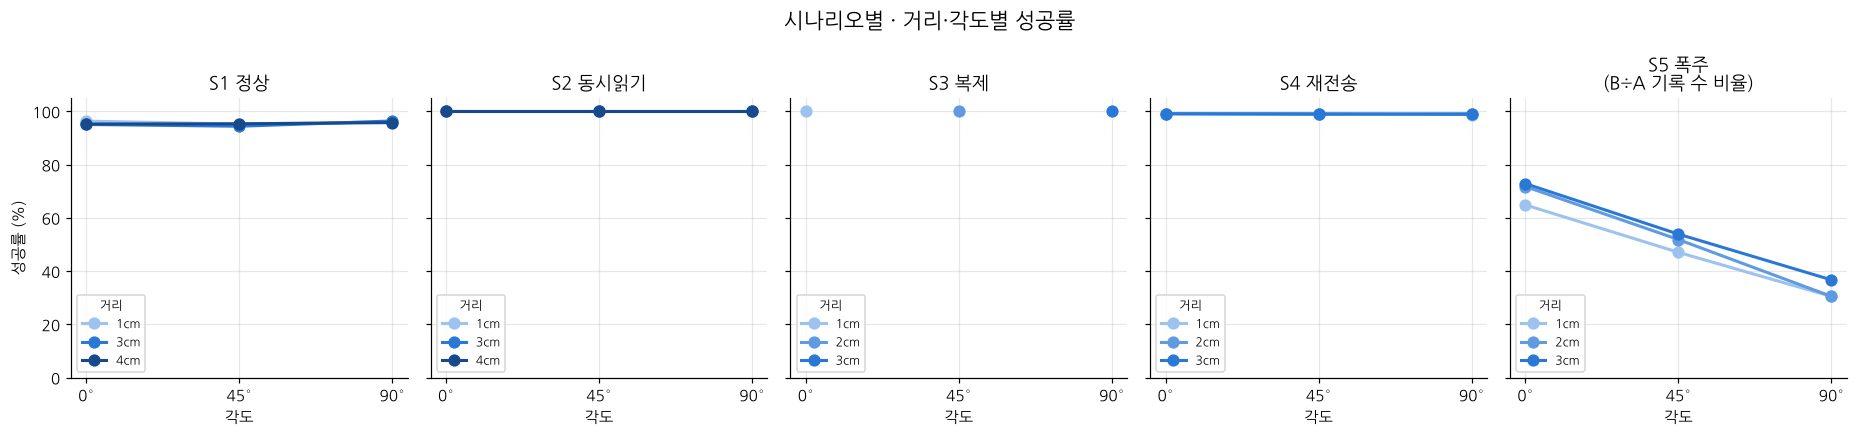

distance_cm                    1       2       3       4
scenario orientation_deg                                
S1       0                 96.34     NaN   95.08   95.25
         45                95.22     NaN   94.42   95.33
         90                96.03     NaN   96.39   95.78
S2       0                100.00     NaN  100.00  100.00
         45               100.00     NaN  100.00  100.00
         90               100.00     NaN  100.00  100.00
S3       0                100.00     NaN     NaN     NaN
         45                  NaN  100.00     NaN     NaN
         90                  NaN     NaN  100.00     NaN
S4       0                 99.12   99.15   99.09     NaN
         45                99.02   98.83   99.09     NaN
         90                98.81   99.17   98.89     NaN
S5       0                 64.88   71.76   72.87     NaN
         45                47.06   51.86   53.90     NaN
         90                30.50   30.52   36.72     NaN

In [8]:
meta1 = read_csv_safe(PROC / "meta_sessions_S1.csv")
meta2 = read_csv_safe(PROC / "meta_sessions_S2.csv")
s5_rate = read_csv_safe(PROC / "s5_success_rates_per_session.csv")

def by_event(d, ok):
    return (d.assign(ok=ok(d)).groupby(["distance_cm", "orientation_deg"])["ok"].mean().mul(100)
              .rename("success").reset_index())

def by_meta(m, col):
    return m.groupby(["distance_cm", "orientation_deg"])[col].mean().rename("success").reset_index()

cond = pd.concat([
    by_meta(meta1, "success_rate").assign(scenario="S1"),
    by_meta(meta2, "success_rate").assign(scenario="S2"),
    by_event(data["S3"], lambda d: d["event"] == "read_success").assign(scenario="S3"),
    by_event(data["S4"], lambda d: d["event"] != "read_fail").assign(scenario="S4"),
    by_meta(plans["S5"].merge(s5_rate, on="session_id"), "success_rate_pct").assign(scenario="S5"),
], ignore_index=True).astype({"distance_cm": int, "orientation_deg": int})

fig, axes = plt.subplots(1, 5, figsize=(17, 4), sharey=True)
for ax, sc in zip(axes, SCENARIOS):
    for dist, g in cond[cond["scenario"] == sc].groupby("distance_cm"):
        g = g.sort_values("orientation_deg")
        ax.plot(g["orientation_deg"], g["success"], marker="o", ms=7, lw=2, color=DIST_COLOR[dist], label=f"{dist}cm")
    ax.set_title(SC_NAME[sc] + ("\n(B÷A 기록 수 비율)" if sc == "S5" else ""))
    ax.set_xticks([0, 45, 90], ["0°", "45°", "90°"])
    ax.set_xlabel("각도")
    ax.set_ylim(0, 105)
    ax.legend(title="거리", fontsize=8, title_fontsize=8, loc="lower left")
axes[0].set_ylabel("성공률 (%)")
fig.suptitle("시나리오별 · 거리·각도별 성공률", fontsize=14)
plt.tight_layout()
save(fig, "비교_거리각도별_성공률")
plt.show()
cond.pivot_table(index=["scenario", "orientation_deg"], columns="distance_cm", values="success").round(2)

### 2-2. 기록 간격 비교 (같은 세션·같은 리더기에서 직전 기록과의 간격)

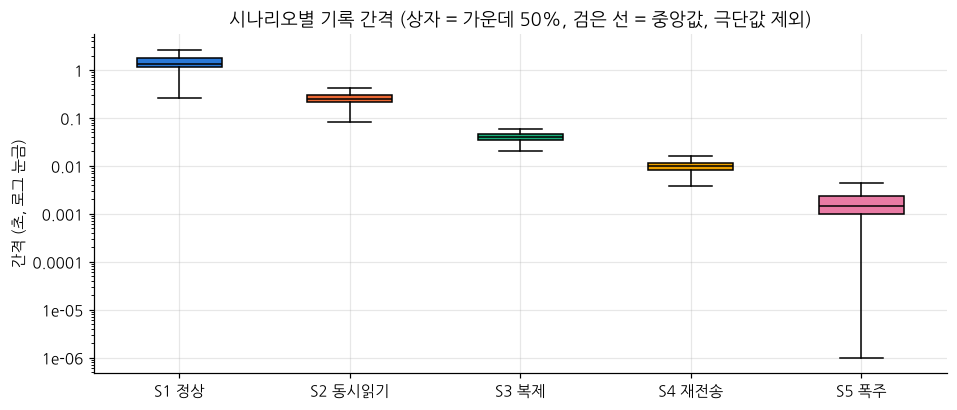

,count,mean,std,min,5%,50%,95%,max
S1 정상,12788.0,11.0782,855.6691,0.0005,1.0274,1.3503,5.1094,95582.2300
S2 동시읽기,31560.0,0.2549,0.1061,0.0001,0.0585,0.2512,0.4571,1.0030
S3 복제,32184.0,0.0400,0.0085,0.0200,0.0260,0.0400,0.0540,0.0600
S4 재전송,41646.0,0.0099,0.0038,0.0000,0.0032,0.0099,0.0166,0.0314
S5 폭주,289437.0,0.0024,0.0216,0.0000,0.0006,0.0014,0.0055,1.0140


In [9]:
fig, ax = plt.subplots(figsize=(10, 4))
iv_list = [data[sc]["간격_초"].dropna().loc[lambda s: s > 0] for sc in SCENARIOS]
bp = ax.boxplot(iv_list, tick_labels=[SC_NAME[sc] for sc in SCENARIOS], patch_artist=True, showfliers=False,
                medianprops={"color": "black"})
for patch, sc in zip(bp["boxes"], SCENARIOS):
    patch.set_facecolor(SC_COLOR[sc])
ax.set_yscale("log")
ax.yaxis.set_major_formatter(plain)
ax.set_ylabel("간격 (초, 로그 눈금)")
ax.set_title("시나리오별 기록 간격 (상자 = 가운데 50%, 검은 선 = 중앙값, 극단값 제외)")
save(fig, "비교_기록간격")
plt.show()
pd.DataFrame({SC_NAME[sc]: s.describe(percentiles=[.05, .5, .95]) for sc, s in zip(SCENARIOS, iv_list)}).T.round(4)

---
## 3. S1 정상 읽기 (S1)
**실험 설명** (`docs/scenarios.md` 요약): 단일 리더기로 태그 12개를 여러 거리·각도에서 읽음. 조건마다 100~150회 읽기 시도.

### S1 기록 요약

In [10]:
기록_요약("S1")

,S1 정상
기록 수,"13,004"
세션 수,108
세션당 기록 수 (최소 / 중앙값 / 최대),100 / 100 / 154
리더기별 기록 수,"ESP32_A 6,546, ESP32_B 6,458"
기록 종류(event)별 수,"read_success 12,472, raw 532"
측정 기간(UTC),2025-11-04 08:12 ~ 2025-11-09 14:44


### S1 기록 예시 (앞 3행)

In [11]:
data["S1"].drop(columns=["ts", "간격_초"]).head(3)

,timestamp_iso,session_id,scenario,device_id,port,tag_local_id,uid_hash,uid_plain_local,distance_cm,orientation_deg,event,raw_payload
0,2025-11-04T08:12:55.469573Z,S20251104_S1_TAG01_d1_o0_run1,S1,ESP32_B,COM4,TAG01,9720a7f2733d,83C11D13,1.0,0.0,read_success,UID: 83 C1 1D 13
1,2025-11-04T08:13:09.703865Z,S20251104_S1_TAG01_d1_o0_run1,S1,ESP32_B,COM4,TAG01,9720a7f2733d,83C11D13,1.0,0.0,read_success,UID: 83 C1 1D 13
2,2025-11-04T08:13:15.142252Z,S20251104_S1_TAG01_d1_o0_run1,S1,ESP32_B,COM4,TAG01,9720a7f2733d,83C11D13,1.0,0.0,read_success,UID: 83 C1 1D 13


### S1 실험 계획표 `s1_plan.csv`: 열마다 어떤 값이 있나

In [12]:
계획표_요약(plans["S1"])

,값 종류 수,값
열,,
session_id,108,"S20251104_S1_TAG01_d1_o0_run1, S20251104_S1_TA..."
tag_local_id,12,"TAG01, TAG02, TAG03, TAG04, TAG05, TAG06 …"
distance_cm,3,"1, 3, 4"
orientation_deg,3,"0, 45, 90"
repetitions,2,"100, 150"


### S1 기록 간격 분포

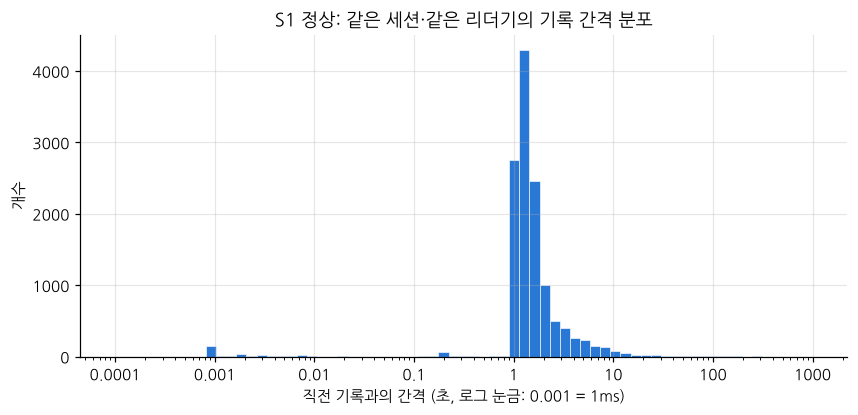

,count,mean,std,min,5%,25%,50%,75%,95%,max
간격_초,12788.0,11.0782,855.6691,0.0005,1.0274,1.1557,1.3503,1.7593,5.1094,95582.23


In [13]:
간격_분포("S1")

### S1 요약 파일 `meta_sessions_S1.csv` (앞 10행)

In [14]:
meta1.head(10)

,session_id,total_reads,success_reads,success_rate,tag_local_id,distance_cm,orientation_deg,repetitions
0,S20251104_S1_TAG01_d1_o0_run1,154,151,98.05,TAG01,1,0,150
1,S20251104_S1_TAG01_d1_o45_run1,150,138,92.00,TAG01,1,45,150
2,S20251104_S1_TAG01_d1_o90_run1,150,150,100.00,TAG01,1,90,150
3,S20251104_S1_TAG01_d3_o0_run1,150,150,100.00,TAG01,3,0,150
4,S20251104_S1_TAG01_d3_o45_run1,150,139,92.67,TAG01,3,45,150
5,S20251104_S1_TAG01_d3_o90_run1,150,150,100.00,TAG01,3,90,150
6,S20251104_S1_TAG01_d4_o0_run1,150,147,98.00,TAG01,4,0,150
7,S20251104_S1_TAG01_d4_o45_run1,150,139,92.67,TAG01,4,45,150
8,S20251104_S1_TAG01_d4_o90_run1,150,150,100.00,TAG01,4,90,150
9,S20251104_S1_TAG02_d1_o0_run1,150,149,99.33,TAG02,1,0,150


### S1 태그별 · 리더기별 기록 수

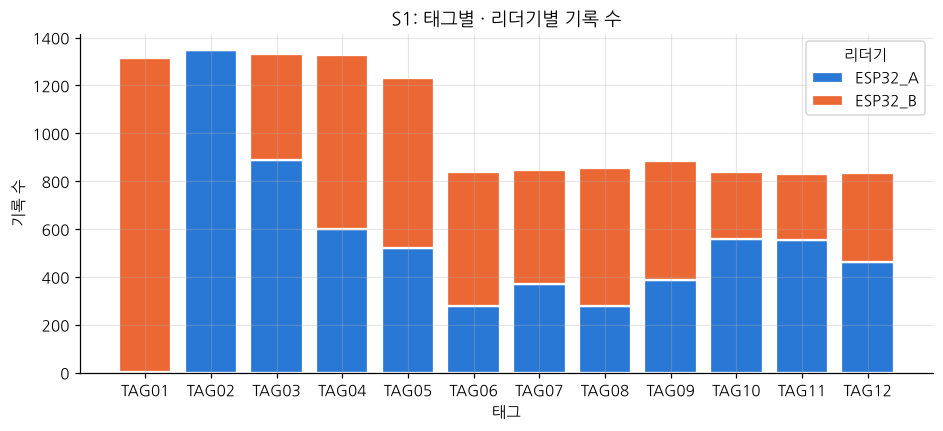

device_id,ESP32_A,ESP32_B
tag_local_id,,
TAG01,1,1313
TAG02,1346,2
TAG03,888,442
TAG04,598,727
TAG05,519,710
TAG06,278,561
TAG07,371,477
TAG08,278,576
TAG09,386,499


In [15]:
tab = pd.crosstab(data["S1"]["tag_local_id"], data["S1"]["device_id"])
fig, ax = plt.subplots(figsize=(10, 4))
bottom = np.zeros(len(tab))
for i, col in enumerate(tab.columns):
    ax.bar(tab.index, tab[col], bottom=bottom, color=COLORS[i], edgecolor="white", linewidth=1.5, label=col)
    bottom += tab[col].values
ax.set_xlabel("태그")
ax.set_ylabel("기록 수")
ax.set_title("S1: 태그별 · 리더기별 기록 수")
ax.legend(title="리더기")
save(fig, "S1_태그별_리더기별_기록수")
plt.show()
tab

---
## 4. S2 동시 읽기 / 충돌 (S2)
**실험 설명** (`docs/scenarios.md` 요약): 리더기 A·B를 동시에 켜고, 두 리더 사이 겹치는 위치에 태그를 둠. 태그마다 150회 반복.

### S2 기록 요약

In [16]:
기록_요약("S2")

,S2 동시읽기
기록 수,"31,776"
세션 수,108
세션당 기록 수 (최소 / 중앙값 / 최대),289 / 294.5 / 299
리더기별 기록 수,"ESP32_A 15,866, ESP32_B 15,910"
기록 종류(event)별 수,"read_success 31,776"
측정 기간(UTC),2025-11-10 13:03 ~ 2025-11-10 13:08


### S2 기록 예시 (앞 3행)

In [17]:
data["S2"].drop(columns=["ts", "간격_초"]).head(3)

,timestamp_iso,session_id,scenario,device_id,port,tag_local_id,uid_hash,uid_plain_local,distance_cm,orientation_deg,event,raw_payload
27664,2025-11-10T13:03:12.032883Z,S20251109_S2_TAG11_d3_o45_run1,S2,ESP32_A,COM9,TAG11,ea5e81f53d69,3EA4F2CF,3,45,read_success,READ_UID:3EA4F2CF
27810,2025-11-10T13:03:12.040749Z,S20251109_S2_TAG11_d3_o45_run1,S2,ESP32_B,COM4,TAG11,ea5e81f53d69,3EA4F2CF,3,45,read_success,READ_UID:3EA4F2CF
27665,2025-11-10T13:03:12.260620Z,S20251109_S2_TAG11_d3_o45_run1,S2,ESP32_A,COM9,TAG11,ea5e81f53d69,3EA4F2CF,3,45,read_success,READ_UID:3EA4F2CF


### S2 실험 계획표 `s2_plan.csv`: 열마다 어떤 값이 있나

In [18]:
계획표_요약(plans["S2"])

,값 종류 수,값
열,,
session_id,108,"S20251109_S2_TAG01_d1_o0_run1, S20251109_S2_TA..."
tag_local_id,12,"TAG01, TAG02, TAG03, TAG04, TAG05, TAG06 …"
distance_cm,3,"1, 3, 4"
orientation_deg,3,"0, 45, 90"
repetitions,1,150


### S2 기록 간격 분포

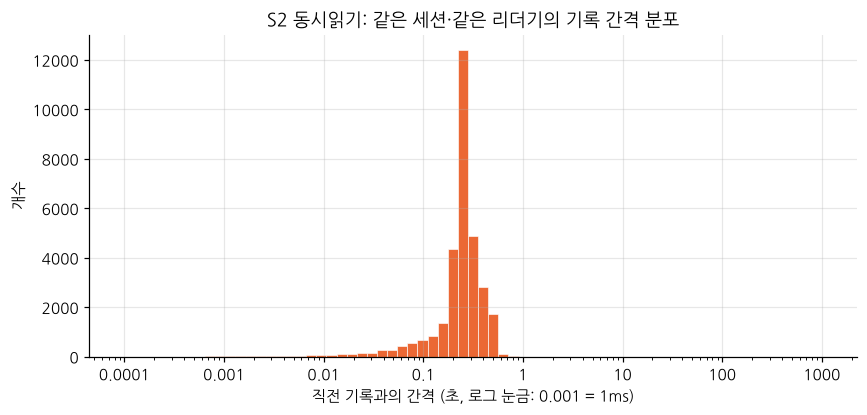

,count,mean,std,min,5%,25%,50%,75%,95%,max
간격_초,31560.0,0.2549,0.1061,0.0001,0.0585,0.2102,0.2512,0.2943,0.4571,1.003


In [19]:
간격_분포("S2")

### S2 요약 파일 `meta_sessions_S2.csv`

In [20]:
meta2

,reader,distance_cm,orientation_deg,count,mean_rssi,std_rssi,success_rate
0,ESP32_A,1,0,1765,0.0,0.0,100.0
1,ESP32_A,1,45,1753,0.0,0.0,100.0
2,ESP32_A,1,90,1762,0.0,0.0,100.0
3,ESP32_A,3,0,1756,0.0,0.0,100.0
4,ESP32_A,3,45,1764,0.0,0.0,100.0
5,ESP32_A,3,90,1767,0.0,0.0,100.0
6,ESP32_A,4,0,1767,0.0,0.0,100.0
7,ESP32_A,4,45,1765,0.0,0.0,100.0
8,ESP32_A,4,90,1767,0.0,0.0,100.0
9,ESP32_B,1,0,1772,0.0,0.0,100.0


### S2 요약 파일 `s2_collisions_summary.csv`: A와 B 기록 시각의 차이

,session_id,uid,tA,tB,dt
0,S20251109_S2_TAG01_d1_o0_run1,0996BA5E,2025-11-10T13:07:18.723201Z,2025-11-10T13:07:18.709772Z,0.013429
1,S20251109_S2_TAG01_d1_o0_run1,0996BA5E,2025-11-10T13:07:18.723201Z,2025-11-10T13:07:18.948621Z,-0.225420
2,S20251109_S2_TAG01_d1_o0_run1,0996BA5E,2025-11-10T13:07:18.961499Z,2025-11-10T13:07:18.948621Z,0.012878
3,S20251109_S2_TAG01_d1_o0_run1,0996BA5E,2025-11-10T13:07:18.961499Z,2025-11-10T13:07:19.195498Z,-0.233999
4,S20251109_S2_TAG01_d1_o0_run1,0996BA5E,2025-11-10T13:07:19.219279Z,2025-11-10T13:07:19.195498Z,0.023781


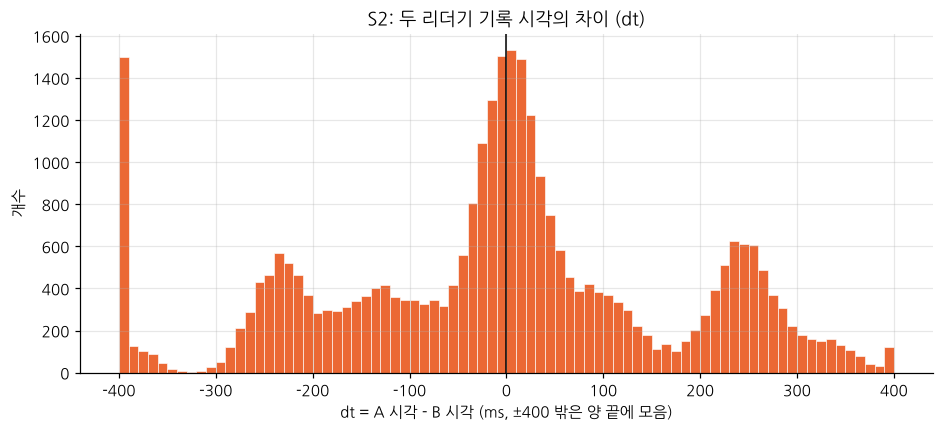

,count,mean,std,min,25%,50%,75%,max
dt_ms,31664.0,-9.94,188.84,-739.83,-125.12,0.03,93.76,760.59


In [21]:
s2_pairs = read_csv_safe(PROC / "s2_collisions_summary.csv")
display(s2_pairs.head())
dt_ms = s2_pairs["dt"] * 1000
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(dt_ms.clip(-400, 400), bins=80, color=SC_COLOR["S2"], edgecolor="white", linewidth=0.4)
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("dt = A 시각 - B 시각 (ms, ±400 밖은 양 끝에 모음)")
ax.set_ylabel("개수")
ax.set_title("S2: 두 리더기 기록 시각의 차이 (dt)")
save(fig, "S2_AB_시간차")
plt.show()
dt_ms.describe().round(2).to_frame("dt_ms").T

---
## 5. S3 태그 복제 / UID 중복 (S3)
**실험 설명** (`docs/scenarios.md` 요약): 같은 UID를 가진 태그(복제 또는 같은 UID로 지정한 태그 쌍)가 함께 있을 때를 관찰. 쌍(pair)마다 3회.

### S3 기록 요약

In [22]:
기록_요약("S3")

,S3 복제
기록 수,"32,400"
세션 수,108
세션당 기록 수 (최소 / 중앙값 / 최대),300 / 300 / 300
리더기별 기록 수,"ESP32_A 16,200, ESP32_B 16,200"
기록 종류(event)별 수,"read_success 32,400"
측정 기간(UTC),2025-11-11 10:38 ~ 2025-11-11 10:38


### S3 기록 예시 (앞 3행)

In [23]:
data["S3"].drop(columns=["ts", "간격_초"]).head(3)

,timestamp_iso,session_id,scenario,device_id,port,tag_local_id,uid_hash,uid_plain_local,distance_cm,orientation_deg,event,raw_payload
9000,2025-11-11T10:38:05.607816Z,S20251110_S3_P1_run1,S3,ESP32_A,COM9,TAG01,83c11d13,83C11D13,1,0,read_success,READ_UID:83C11D13
19200,2025-11-11T10:38:05.607817Z,S20251110_S3_P2_run2,S3,ESP32_A,COM9,TAG01,83c11d13,83C11D13,2,45,read_success,READ_UID:83C11D13
19350,2025-11-11T10:38:05.607818Z,S20251110_S3_P2_run2,S3,ESP32_B,COM4,TAG01,83c11d13,83C11D13,2,45,read_success,READ_UID:83C11D13


### S3 실험 계획표 `s3_plan.csv`: 열마다 어떤 값이 있나

In [24]:
계획표_요약(plans["S3"])

,값 종류 수,값
열,,
pair_id,36,"P1, P2, P3, P4, P5, P6 …"
tag_id,12,"TAG01, TAG02, TAG03, TAG04, TAG05, TAG06 …"
uid_original,12,"83C11D13, C7F644, 3E2744, 3D9F24, 5E4A44, 8AA34 …"
uid_clone,12,"83C11D13, C7F644, 3E2744, 3D9F24, 5E4A44, 8AA34 …"
distance_cm,3,"1, 2, 3"
orientation_deg,3,"0, 45, 90"
runs,1,3
expected_relation,1,identical
notes,36,"Clone of TAG01 at short distance (0°), Clone o..."


### S3 기록 간격 분포

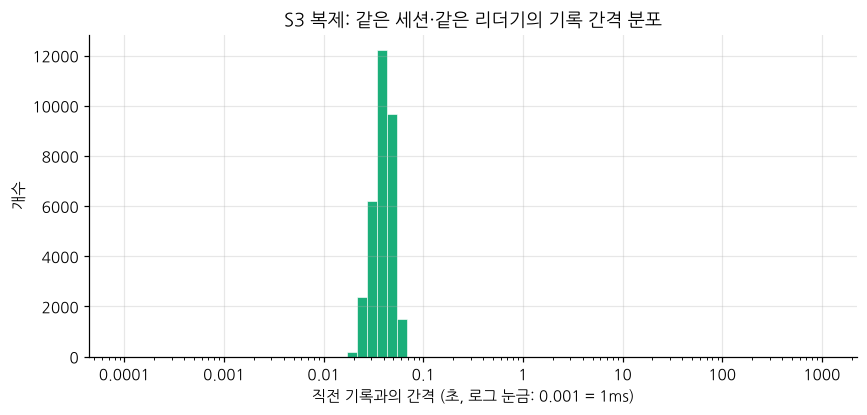

,count,mean,std,min,5%,25%,50%,75%,95%,max
간격_초,32184.0,0.04,0.0085,0.02,0.026,0.034,0.04,0.046,0.054,0.06


In [25]:
간격_분포("S3")

### S3 요약 파일 `s3_summary_counts.csv`

In [26]:
read_csv_safe(PROC / "s3_summary_counts.csv").pivot(index="tag_local_id", columns="device_id", values="read_count")

device_id,ESP32_A,ESP32_B
tag_local_id,,
TAG01,1350,1350
TAG02,1350,1350
TAG03,1350,1350
TAG04,1350,1350
TAG05,1350,1350
TAG06,1350,1350
TAG07,1350,1350
TAG08,1350,1350
TAG09,1350,1350


### S3 요약 파일 `s3_clone_collisions_summary.csv`: 같은 UID가 두 리더에 기록된 시각의 차이

,session_id,uid_hash,uid_plain_local,t_reader_A,t_reader_B,delta_ms
0,S20251110_S3_P10_run1,3d9f24,3D9F24,2025-11-11T10:38:05.680329,2025-11-11T10:38:05.681329,1.0
1,S20251110_S3_P10_run1,3d9f24,3D9F24,2025-11-11T10:38:05.715329,2025-11-11T10:38:05.720329,5.0
2,S20251110_S3_P10_run1,3d9f24,3D9F24,2025-11-11T10:38:05.805329,2025-11-11T10:38:05.800329,5.0
3,S20251110_S3_P10_run1,3d9f24,3D9F24,2025-11-11T10:38:05.837329,2025-11-11T10:38:05.835329,2.0
4,S20251110_S3_P10_run1,3d9f24,3D9F24,2025-11-11T10:38:05.890329,2025-11-11T10:38:05.893329,3.0


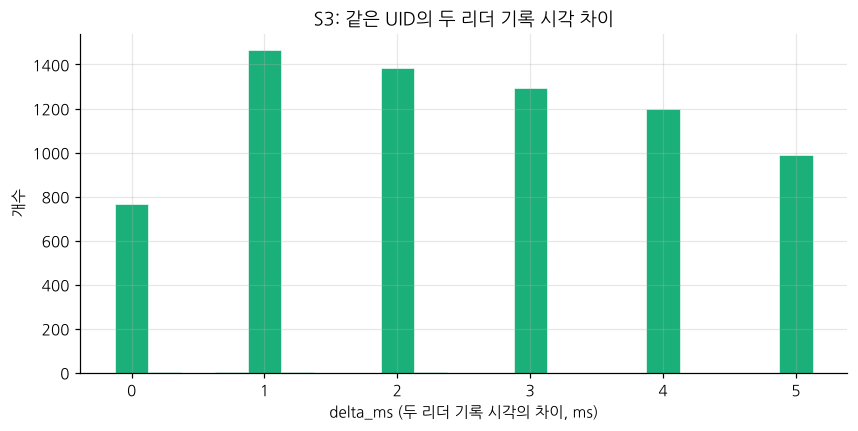

,count,mean,std,min,25%,50%,75%,max
delta_ms,7100.0,2.514,1.576,0.0,1.0,2.001,4.0,5.0


In [27]:
s3_pairs = read_csv_safe(PROC / "s3_clone_collisions_summary.csv")
display(s3_pairs.head())
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(s3_pairs["delta_ms"], bins=np.arange(-0.125, s3_pairs["delta_ms"].max() + 0.25, 0.25), color=SC_COLOR["S3"], edgecolor="white", linewidth=0.4)
ax.set_xlabel("delta_ms (두 리더 기록 시각의 차이, ms)")
ax.set_ylabel("개수")
ax.set_title("S3: 같은 UID의 두 리더 기록 시각 차이")
save(fig, "S3_두리더_시간차")
plt.show()
s3_pairs["delta_ms"].describe().round(3).to_frame("delta_ms").T

---
## 6. S4 재전송(Replay) / 주입 (S4)
**실험 설명** (`docs/scenarios.md` 요약): 리더 A가 정상 태그를 읽는 동안, 리더 B 쪽에서 같은 UID를 복제 태그·휴대폰 에뮬레이션·소프트웨어 주입으로 다시 넣음.

### S4 기록 요약

In [28]:
기록_요약("S4")

,S4 재전송
기록 수,"41,719"
세션 수,36
세션당 기록 수 (최소 / 중앙값 / 최대),1000 / 1001 / 1502
리더기별 기록 수,"ESP32_A 21,065, ESP32_B 20,654"
기록 종류(event)별 수,"read_success 31,050, read_injected 10,258, rea..."
측정 기간(UTC),2025-11-10 11:47 ~ 2025-11-10 11:48


### S4 기록 예시 (앞 3행)

In [29]:
data["S4"].drop(columns=["ts", "간격_초"]).head(3)

,timestamp_iso,session_id,scenario,device_id,port,tag_local_id,uid_hash,uid_plain_local,distance_cm,orientation_deg,event,raw_payload,reader,source_file
0,2025-11-10T11:47:40.783797Z,S4_TAG03_run3,S4,ESP32_A,COM9,TAG03,2377930,3E2744,1.0,90,read_success,READ_UID:3E2744,A,session_S4_TAG03_run3_ESP32_A.jsonl
1,2025-11-10T11:47:40.793104Z,S4_TAG03_run3,S4,ESP32_A,COM9,TAG03,2377930,3E2744,1.0,90,read_success,READ_UID:3E2744,A,session_S4_TAG03_run3_ESP32_A.jsonl
2,2025-11-10T11:47:40.797387Z,S4_TAG03_run3,S4,ESP32_B,COM4,TAG03,2377930,3E2744,1.0,90,read_injected,INJECTED_READ_FROM:stored_capture;UID:3E2744,B,session_S4_TAG03_run3_ESP32_B.jsonl


### S4 실험 계획표 `s4_plan.csv`: 열마다 어떤 값이 있나

In [30]:
계획표_요약(plans["S4"])

,값 종류 수,값
열,,
session_id,36,"S4_TAG01_run1, S4_TAG01_run2, S4_TAG01_run3, S..."
tag_local_id,12,"TAG01, TAG02, TAG03, TAG04, TAG05, TAG06 …"
mode,1,REPLAY
device_A_port,1,COM9
device_B_port,1,COM4
distance_cm,3,"1, 2, 3"
orientation_deg,3,"0, 45, 90"
replay_type,3,"physical_clone, mobile_emulation, software_inj..."
replay_source,8,"TAG01, TAG02, stored_capture, TAG05, TAG06, TA..."


### S4 기록 간격 분포

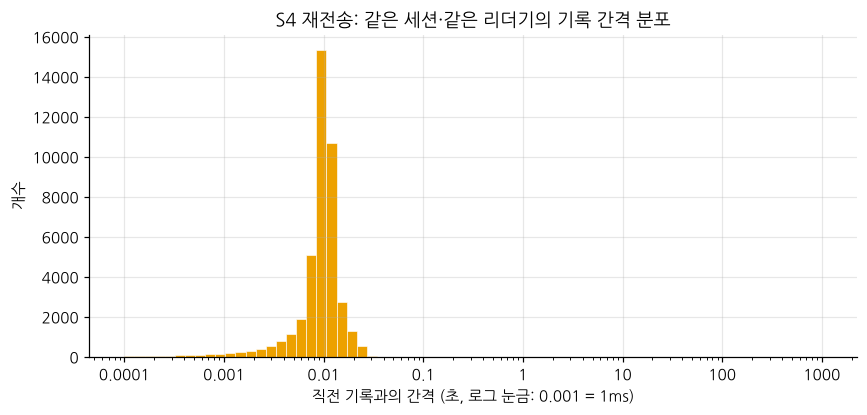

,count,mean,std,min,5%,25%,50%,75%,95%,max
간격_초,41646.0,0.0099,0.0038,0.0,0.0032,0.0084,0.0099,0.0114,0.0166,0.0314


In [31]:
간격_분포("S4")

### S4 재전송 방식(`replay_type`)별 기록 종류 비율

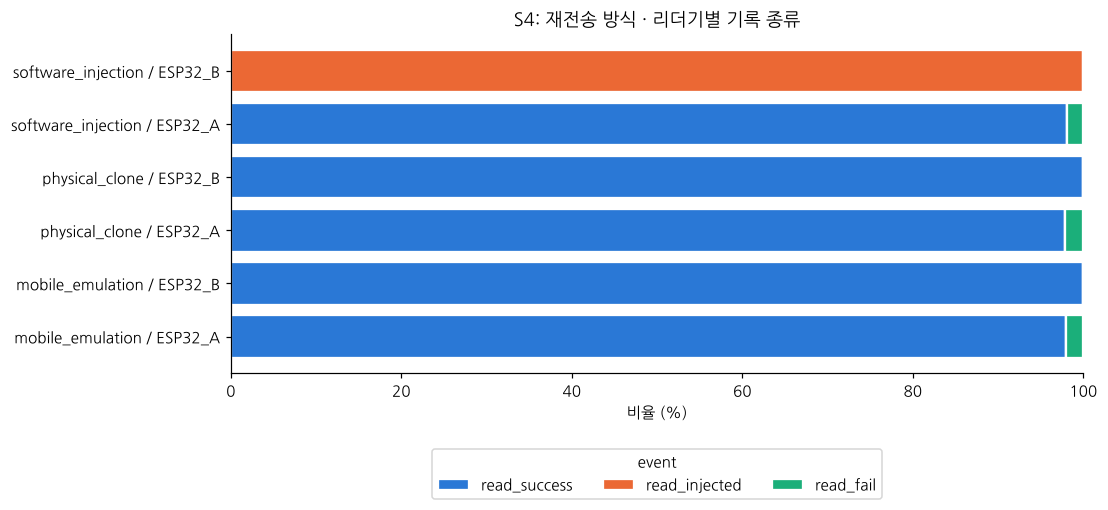

event                         read_success  read_injected  read_fail
replay_type        device_id                                        
mobile_emulation   ESP32_A           98.02            0.0       1.98
                   ESP32_B          100.00            0.0       0.00
physical_clone     ESP32_A           97.91            0.0       2.09
                   ESP32_B          100.00            0.0       0.00
software_injection ESP32_A           98.14            0.0       1.86
                   ESP32_B            0.00          100.0       0.00

In [32]:
s4 = data["S4"].merge(plans["S4"][["session_id", "replay_type"]], on="session_id", how="left")
comp = pd.crosstab([s4["replay_type"], s4["device_id"]], s4["event"], normalize="index").mul(100)
comp = comp[[c for c in ["read_success", "read_injected", "read_fail"] if c in comp]]
fig, ax = plt.subplots(figsize=(10, 4))
left = np.zeros(len(comp))
labels = [f"{a} / {b}" for a, b in comp.index]
for i, col in enumerate(comp.columns):
    ax.barh(labels, comp[col], left=left, color=COLORS[i], edgecolor="white", linewidth=1.5, label=col)
    left += comp[col].values
ax.set_xlabel("비율 (%)")
ax.set_title("S4: 재전송 방식 · 리더기별 기록 종류")
ax.legend(title="event", loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3)
ax.grid(False)
save(fig, "S4_방식별_기록종류")
plt.show()
comp.round(2)

### S4 요약 파일 `s4_replay_summary.csv`: 재전송 지연(delta_ms)

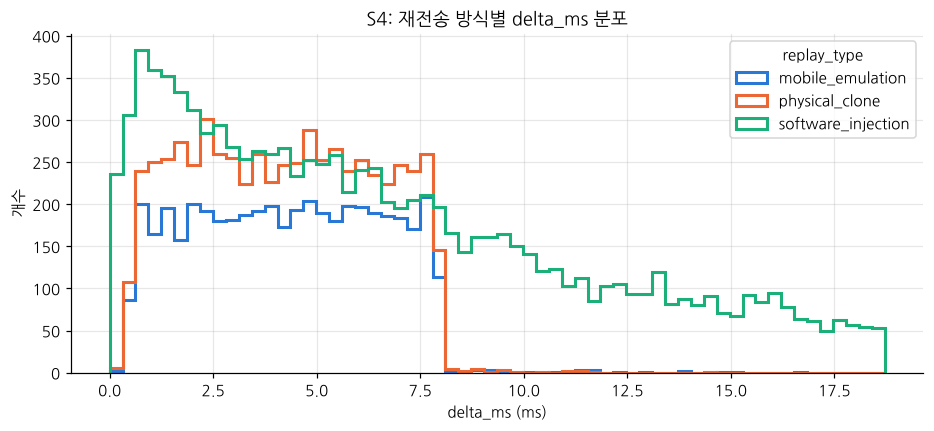

,count,mean,std,min,25%,50%,75%,max
replay_type,,,,,,,,
mobile_emulation,4547.0,4.29,2.22,0.19,2.39,4.30,6.13,16.64
physical_clone,6065.0,4.22,2.18,0.05,2.33,4.22,6.05,14.57
software_injection,10450.0,6.82,5.11,0.00,2.54,5.70,10.02,22.18


In [33]:
s4_rep = read_csv_safe(PROC / "s4_replay_summary.csv").merge(plans["S4"][["session_id", "replay_type"]], on="session_id", how="left")
fig, ax = plt.subplots(figsize=(10, 4))
for i, (kind, g) in enumerate(s4_rep.groupby("replay_type")):
    ax.hist(g["delta_ms"], bins=60, range=(0, s4_rep["delta_ms"].quantile(0.99)), histtype="step", lw=2, color=COLORS[i], label=kind)
ax.set_xlabel("delta_ms (ms)")
ax.set_ylabel("개수")
ax.set_title("S4: 재전송 방식별 delta_ms 분포")
ax.legend(title="replay_type")
save(fig, "S4_재전송지연")
plt.show()
s4_rep.groupby("replay_type")["delta_ms"].describe().round(2)

---
## 7. S5 고속 읽기 / 폭주(DoS 유사) (S5)
**실험 설명** (`docs/scenarios.md` 요약): 짧은 시간에 대량의 읽기 시도(버스트 1,000~5,000회)를 반복해 리더기에 부하를 줌.

### S5 기록 요약

In [34]:
기록_요약("S5")

,S5 폭주
기록 수,"289,523"
세션 수,36
세션당 기록 수 (최소 / 중앙값 / 최대),4461 / 8433 / 11950
리더기별 기록 수,"ESP32_A 194,700, ESP32_B 94,823"
기록 종류(event)별 수,"read_success 289,523"
측정 기간(UTC),2025-11-11 12:09 ~ 2025-11-11 12:09


### S5 기록 예시 (앞 3행)

In [35]:
data["S5"].drop(columns=["ts", "간격_초"]).head(3)

,timestamp_iso,session_id,scenario,device_id,port,tag_local_id,uid_plain_local,event,raw_payload
0,2025-11-11T12:09:29.134068Z,S5_TAG01_run1,S5,ESP32_A,COM9,TAG01,TAG01,read_success,READ_UID:TAG01
3001,2025-11-11T12:09:29.135235Z,S5_TAG01_run1,S5,ESP32_B,COM4,TAG01,TAG01,read_success,READ_UID:TAG01
3000,2025-11-11T12:09:29.136053Z,S5_TAG01_run1,S5,ESP32_B,COM4,TAG01,TAG01,read_success,READ_UID:TAG01


### S5 실험 계획표 `s5_plan.csv`: 열마다 어떤 값이 있나

In [36]:
계획표_요약(plans["S5"])

,값 종류 수,값
열,,
session_id,36,"S5_TAG01_run1, S5_TAG01_run2, S5_TAG01_run3, S..."
tag_local_id,12,"TAG01, TAG02, TAG03, TAG04, TAG05, TAG06 …"
mode,1,FLOOD
device_A_port,1,COM9
device_B_port,1,COM4
distance_cm,3,"1, 2, 3"
orientation_deg,3,"0, 45, 90"
burst_size,12,"1000, 1200, 1500, 1800, 2000, 2200, 2500, 3000..."
burst_rate_hz,15,300 ~ 1200


### S5 기록 간격 분포

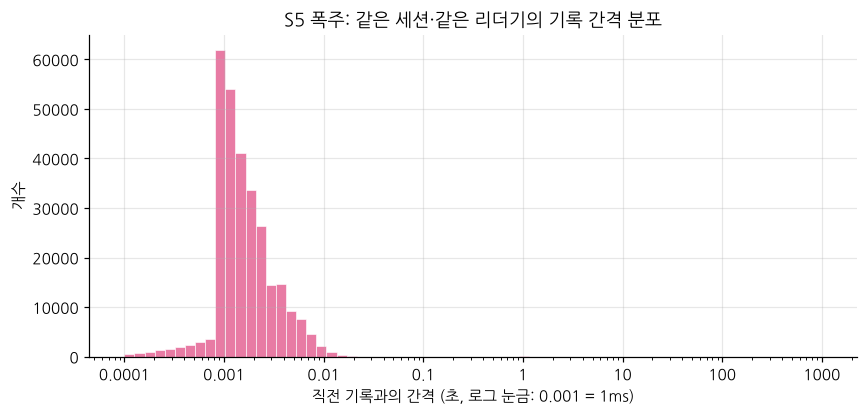

,count,mean,std,min,5%,25%,50%,75%,95%,max
간격_초,289437.0,0.0024,0.0216,0.0,0.0006,0.001,0.0014,0.0023,0.0055,1.014


In [37]:
간격_분포("S5")

### S5 요약 파일 `s5_success_rates_per_session.csv`

In [38]:
s5_rate

,session_id,reads_A,reads_B,success_rate_pct
0,S5_TAG01_run1,3000,1948,64.933333
1,S5_TAG01_run2,6000,2854,47.566667
2,S5_TAG01_run3,6000,2032,33.866667
3,S5_TAG02_run1,4000,2926,73.150000
4,S5_TAG02_run2,6000,3191,53.183333
5,S5_TAG02_run3,5000,1666,33.320000
6,S5_TAG03_run1,5000,4018,80.360000
7,S5_TAG03_run2,6000,3520,58.666667
8,S5_TAG03_run3,8000,3159,39.487500
9,S5_TAG04_run1,3000,2031,67.700000


### S5 세션별 리더기 A · B 기록 수

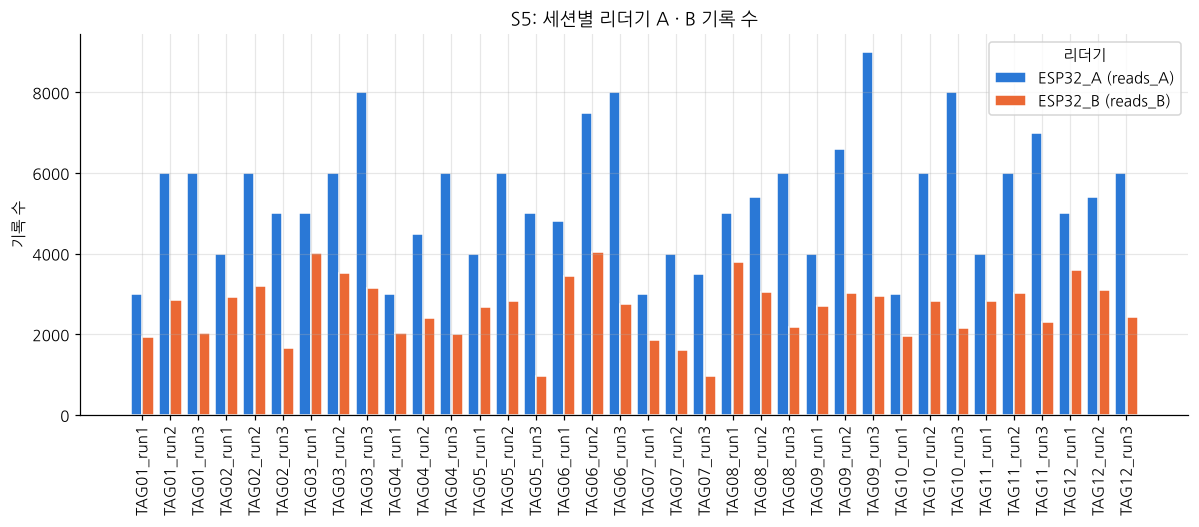

,reads_A,reads_B
count,36.0,36.0
mean,5408.3,2634.0
std,1546.1,757.0
min,3000.0,961.0
25%,4000.0,2031.8
50%,5400.0,2781.0
75%,6000.0,3057.5
max,9000.0,4036.0


In [39]:
labels = s5_rate["session_id"].str.replace("S5_", "")
x = np.arange(len(s5_rate))
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.bar(x - 0.21, s5_rate["reads_A"], width=0.4, color=COLORS[0], edgecolor="white", label="ESP32_A (reads_A)")
ax.bar(x + 0.21, s5_rate["reads_B"], width=0.4, color=COLORS[1], edgecolor="white", label="ESP32_B (reads_B)")
ax.set_xticks(x, labels, rotation=90)
ax.set_ylabel("기록 수")
ax.set_title("S5: 세션별 리더기 A · B 기록 수")
ax.legend(title="리더기")
save(fig, "S5_세션별_리더기별_기록수")
plt.show()
s5_rate[["session_id", "reads_A", "reads_B"]].describe().round(1)

### S5 세션별 B ÷ A 기록 수 비율 (요약 파일의 `success_rate_pct`)

요약 파일의 success_rate_pct와 직접 계산한 B÷A×100의 최대 차이: 0.0


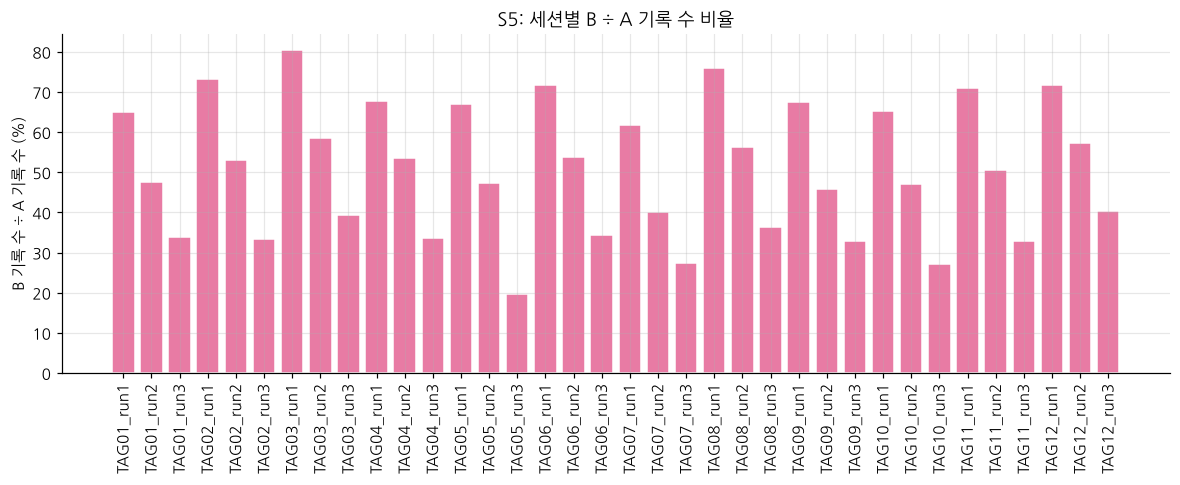

In [40]:
ratio = s5_rate["reads_B"] / s5_rate["reads_A"] * 100
print("요약 파일의 success_rate_pct와 직접 계산한 B÷A×100의 최대 차이:", (ratio - s5_rate["success_rate_pct"]).abs().max().round(6))
fig, ax = plt.subplots(figsize=(13, 4))
ax.bar(labels, ratio, color=SC_COLOR["S5"], edgecolor="white")
ax.set_ylabel("B 기록 수 ÷ A 기록 수 (%)")
ax.set_title("S5: 세션별 B ÷ A 기록 수 비율")
ax.tick_params(axis="x", rotation=90)
save(fig, "S5_세션별_BA비율")
plt.show()

### S5 한 세션의 시간에 따른 기록 수 (`SID`를 바꿔 다른 세션도 볼 수 있어요)

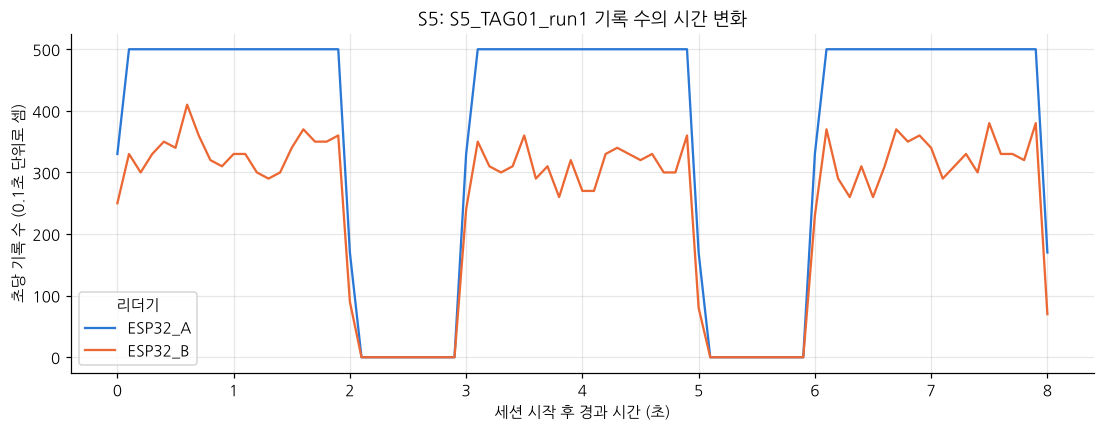

In [41]:
SID = "S5_TAG01_run1"
g = data["S5"][data["S5"]["session_id"] == SID]
t0 = g["ts"].min().floor("100ms")
fig, ax = plt.subplots(figsize=(12, 4))
for i, (dev, gg) in enumerate(g.groupby("device_id")):
    per = gg.set_index("ts").resample("100ms").size()
    ax.plot((per.index - t0).total_seconds(), per.values * 10, lw=1.5, color=COLORS[i], label=dev)
ax.set_xlabel("세션 시작 후 경과 시간 (초)")
ax.set_ylabel("초당 기록 수 (0.1초 단위로 셈)")
ax.set_title(f"S5: {SID} 기록 수의 시간 변화")
ax.legend(title="리더기")
save(fig, f"S5_시계열_{SID}")
plt.show()

---
## 그래프 내려받기

In [42]:
for p in sorted(FIG_DIR.glob("*.png")):
    print(p.name)
shutil.make_archive("rfid_figures", "zip", FIG_DIR)
try:
    from google.colab import files
    files.download("rfid_figures.zip")
except ImportError:
    print("Colab이 아니면 outputs/figures 폴더에서 바로 꺼내 쓰면 됩니다.")

S1_기록간격_분포.png
S1_태그별_리더기별_기록수.png
S2_AB_시간차.png
S2_기록간격_분포.png
S3_기록간격_분포.png
S3_두리더_시간차.png
S4_기록간격_분포.png
S4_방식별_기록종류.png
S4_재전송지연.png
S5_기록간격_분포.png
S5_세션별_BA비율.png
S5_세션별_리더기별_기록수.png
S5_시계열_S5_TAG01_run1.png
비교_거리각도별_성공률.png
비교_기록간격.png
Colab이 아니면 outputs/figures 폴더에서 바로 꺼내 쓰면 됩니다.
